# 03 — ResNet-18 Transfer Learning

**Project:** Brain MRI Image Classification and Explainable AI  
**Notebook goal:** fine-tune an ImageNet-pretrained ResNet-18, select the checkpoint by validation macro-F1, evaluate on the same official and exact-duplicate-filtered test subsets as notebook 02, and compare the results with the custom CNN baseline.

## What this notebook produces

- `models/resnet18.pt` — selected checkpoint and experiment metadata
- `results/resnet18_history.csv` — per-epoch training and validation metrics
- `results/resnet18_metrics.json` — configuration and final test metrics
- `results/resnet18_classification_report.csv` — class-wise test metrics
- `results/resnet18_predictions.csv` — test predictions and probabilities
- `results/model_comparison.csv` — side-by-side CNN/ResNet comparison, when notebook 02 results exist
- `results/visualizations/resnet18_*.png` — learning curves, confusion matrices and a Grad-CAM example

## Prerequisites

1. Run notebooks `01_eda_and_data_audit.ipynb` and `02_custom_cnn.ipynb` first.
2. Download the [Brain Tumor MRI Dataset by Masoud Nickparvar from Kaggle](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset) and extract it under `data/`.
3. Ensure `results/model_data_split.csv` and `models/custom_cnn.pt` have been produced by notebook 02.
4. Install the project requirements. The first use of `ResNet18_Weights.DEFAULT` may download pretrained weights from torchvision. If you are offline, set `USE_PRETRAINED_WEIGHTS = False`, but clearly record that this is **not** an ImageNet-pretrained transfer-learning run.

> **Evaluation rules:** this notebook reuses the saved train/validation/test manifest from notebook 02. Validation macro-F1 chooses the checkpoint. The test set is not used for checkpoint selection. The exact-duplicate-filtered test set is a sensitivity analysis, not a guarantee of patient-level independence. This is an educational project, not a clinically validated diagnostic system.

## 1. Imports and reproducibility

Run `pip install -r requirements.txt` from the project root before running the notebook.

In [1]:
from pathlib import Path
import json
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display

import sklearn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

torch.set_num_threads(max(1, min(4, torch.get_num_threads())))
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("PyTorch:", torch.__version__)
print("torchvision model: ResNet-18")
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())

d:\computer vision\Brain-MRI-Classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.5.1+cu121
torchvision model: ResNet-18
scikit-learn: 1.9.1
CUDA available: True


## 2. Configuration and output paths

Defaults are intended for a first GPU-backed run. If training is slow or memory is limited, reduce `BATCH_SIZE` to 16 or 8. `NUM_WORKERS = 0` improves compatibility with Windows notebooks.

In [2]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD
DATA_BASE = PROJECT_ROOT / "data"
DATASET_ROOT_OVERRIDE = None  # Example: Path(r"D:/datasets/brain-tumor-mri-dataset")
RESULTS_DIR = PROJECT_ROOT / "results"
VIS_DIR = RESULTS_DIR / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (RESULTS_DIR, VIS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = RESULTS_DIR / "model_data_split.csv"
CNN_METRICS_PATH = RESULTS_DIR / "custom_cnn_metrics.json"
CHECKPOINT_PATH = MODELS_DIR / "resnet18.pt"
HISTORY_PATH = RESULTS_DIR / "resnet18_history.csv"
METRICS_PATH = RESULTS_DIR / "resnet18_metrics.json"
REPORT_PATH = RESULTS_DIR / "resnet18_classification_report.csv"
PREDICTIONS_PATH = RESULTS_DIR / "resnet18_predictions.csv"
COMPARISON_PATH = RESULTS_DIR / "model_comparison.csv"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 12
HEAD_ONLY_EPOCHS = 2       # Train only the final classification head initially.
HEAD_LEARNING_RATE = 1e-3
LAYER4_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 4
NUM_WORKERS = 0
USE_PRETRAINED_WEIGHTS = True

# Standard ImageNet normalization for torchvision ImageNet-pretrained ResNet-18.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Dataset search root:", DATA_BASE)
print("Shared split manifest:", SPLIT_PATH)
print("Device:", DEVICE)
print("Image size:", IMG_SIZE, "| batch size:", BATCH_SIZE, "| max epochs:", EPOCHS)

Project root: D:\computer vision\Brain-MRI-Classification
Dataset search root: D:\computer vision\Brain-MRI-Classification\data
Shared split manifest: D:\computer vision\Brain-MRI-Classification\results\model_data_split.csv
Device: cuda
Image size: 224 | batch size: 32 | max epochs: 12


## 3. Load the exact split created by notebook 02

This notebook deliberately does **not** create a new split. It reads `results/model_data_split.csv` so the custom CNN, ResNet-18 and later ViT experiment can be compared on matching partitions. The manifest stores paths relative to the dataset root; the helper below locates the corresponding `Training`/`Testing` or `train`/`test` folder pair.

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
TRAIN_NAMES = {"training", "train"}
TEST_NAMES = {"testing", "test"}


def class_dirs_with_images(split_dir: Path):
    if not split_dir.is_dir():
        return []
    return [
        child for child in sorted(split_dir.iterdir())
        if child.is_dir() and any(
            path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
            for path in child.rglob("*")
        )
    ]


def find_dataset_root(search_root: Path) -> Path:
    if not search_root.exists():
        raise FileNotFoundError(
            f"Dataset root not found: {search_root}. Download/extract the Kaggle dataset under data/ "
            "or change DATA_BASE in the configuration cell."
        )
    candidate_dirs = [p for p in search_root.rglob("*") if p.is_dir()]
    candidate_dirs.append(search_root)
    train_dirs = [p for p in candidate_dirs if p.name.lower() in TRAIN_NAMES and class_dirs_with_images(p)]
    test_dirs = [p for p in candidate_dirs if p.name.lower() in TEST_NAMES and class_dirs_with_images(p)]
    pairs = [(tr, te) for tr in train_dirs for te in test_dirs if tr.parent == te.parent]
    if not pairs:
        raise FileNotFoundError(
            "Could not find matching Training/Testing (or train/test) directories with class folders. "
            f"Searched: {search_root}. Check the layout documented in README.md."
        )
    pairs.sort(key=lambda pair: len(pair[0].parts) + len(pair[1].parts))
    return pairs[0][0].parent


if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        f"Missing {SPLIT_PATH}. Run notebooks/02_custom_cnn.ipynb first; it creates the shared split manifest."
    )

DATASET_ROOT = Path(DATASET_ROOT_OVERRIDE).expanduser().resolve() if DATASET_ROOT_OVERRIDE else find_dataset_root(DATA_BASE)
split_df = pd.read_csv(SPLIT_PATH)
required_columns = {"model_split", "class_name", "relative_path", "sha256"}
missing_columns = required_columns - set(split_df.columns)
if missing_columns:
    raise ValueError(f"Split manifest is missing required columns: {sorted(missing_columns)}")

split_df["model_split"] = split_df["model_split"].astype(str).str.lower().str.strip()
split_df["class_name"] = split_df["class_name"].astype(str).str.lower().str.strip()
split_df["relative_path"] = split_df["relative_path"].astype(str)
split_df["sha256"] = split_df["sha256"].astype(str)
CLASS_NAMES = sorted(split_df["class_name"].dropna().unique().tolist(), key=str.casefold)
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

expected_splits = {"train", "validation", "test"}
actual_splits = set(split_df["model_split"].unique())
if not expected_splits.issubset(actual_splits):
    raise ValueError(f"Manifest must contain {sorted(expected_splits)}; found {sorted(actual_splits)}")
if len(CLASS_NAMES) < 2:
    raise ValueError(f"Expected multiple classes; found: {CLASS_NAMES}")

# Reconstruct absolute paths from the same root used by notebook 02.
split_df["path"] = split_df["relative_path"].map(lambda rel: str((DATASET_ROOT / Path(rel)).resolve()))
missing_paths = split_df.loc[~split_df["path"].map(lambda value: Path(value).is_file()), "relative_path"].tolist()
if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} manifest paths were not found under {DATASET_ROOT}. "
        f"Examples: {missing_paths[:5]}. Correct DATASET_ROOT_OVERRIDE if the dataset moved."
    )

train_df = split_df.loc[split_df["model_split"] == "train"].copy().reset_index(drop=True)
val_df = split_df.loc[split_df["model_split"] == "validation"].copy().reset_index(drop=True)
test_df = split_df.loc[split_df["model_split"] == "test"].copy().reset_index(drop=True)
if any(frame.empty for frame in (train_df, val_df, test_df)):
    raise ValueError("Train, validation and test splits must all contain images.")

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
if train_hashes.intersection(val_hashes):
    raise ValueError("Exact SHA-256 overlap found between training and validation manifest rows. Rebuild/audit the split in notebook 02.")
if not set(CLASS_NAMES).issubset(set(train_df["class_name"])):
    raise ValueError("At least one class is missing from the training split.")

# This secondary test subset excludes exact file hashes present anywhere in the original training folder
# (represented by the saved train + validation rows). It does not guarantee patient-level independence.
train_validation_hashes = set(split_df.loc[split_df["model_split"].isin(["train", "validation"]), "sha256"])
test_exact_filtered_df = test_df.loc[~test_df["sha256"].isin(train_validation_hashes)].copy().reset_index(drop=True)

print("Dataset root:", DATASET_ROOT)
print("Classes:", CLASS_NAMES)
print("Class mapping:", CLASS_TO_IDX)
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Official test: {len(test_df):,}")
print(f"Official test after exact train/test overlap removal: {len(test_exact_filtered_df):,}")
display(split_df.groupby(["model_split", "class_name"]).size().rename("images").reset_index())

Dataset root: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Train: 4,480 | Validation: 1,120 | Official test: 1,600
Official test after exact train/test overlap removal: 1,600


,model_split,class_name,images
0,test,glioma,400
1,test,meningioma,400
2,test,notumor,400
3,test,pituitary,400
4,train,glioma,1120
5,train,meningioma,1120
6,train,notumor,1120
7,train,pituitary,1120
8,validation,glioma,280
9,validation,meningioma,280


## 4. Preprocessing, augmentation and dataloaders

The data split is shared with notebook 02, but image normalization is model-specific: ResNet-18 uses the ImageNet mean and standard deviation expected by its pretrained weights. Augmentation is applied only to training data; validation and test transformations are deterministic. Horizontal flips are not used by default because orientation can carry information in medical imagery.

In [4]:
TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=8),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02), scale=(0.97, 1.03)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class BrainMRIDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, class_to_idx: dict, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image_path = Path(row["path"])
        try:
            with Image.open(image_path) as image_obj:
                image = image_obj.convert("RGB")
        except (UnidentifiedImageError, OSError, ValueError) as exc:
            raise RuntimeError(f"Could not read image {image_path}: {exc}") from exc
        if self.transform is not None:
            image = self.transform(image)
        label = self.class_to_idx[row["class_name"]]
        return image, label, row["relative_path"]


train_dataset = BrainMRIDataset(train_df, CLASS_TO_IDX, TRAIN_TRANSFORM)
val_dataset = BrainMRIDataset(val_df, CLASS_TO_IDX, EVAL_TRANSFORM)
test_dataset = BrainMRIDataset(test_df, CLASS_TO_IDX, EVAL_TRANSFORM)
test_exact_filtered_dataset = BrainMRIDataset(test_exact_filtered_df, CLASS_TO_IDX, EVAL_TRANSFORM)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_common
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_common)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_common)
test_exact_filtered_loader = DataLoader(test_exact_filtered_dataset, shuffle=False, **loader_common)

print({
    "train": len(train_dataset),
    "validation": len(val_dataset),
    "official_test": len(test_dataset),
    "test_exact_duplicate_filtered": len(test_exact_filtered_dataset),
})

{'train': 4480, 'validation': 1120, 'official_test': 1600, 'test_exact_duplicate_filtered': 1600}


## 5. Build ResNet-18 with a four-class head

The model starts from ImageNet pretrained weights, replaces the final fully connected layer, and initially freezes the feature extractor. After the head-only warm-up, `layer4` is unfrozen for partial fine-tuning. Earlier layers remain frozen to reduce compute and limit overfitting on this modest dataset.

In [5]:
if USE_PRETRAINED_WEIGHTS:
    try:
        weights = ResNet18_Weights.DEFAULT
        model = resnet18(weights=weights)
        weights_name = "ResNet18_Weights.DEFAULT (ImageNet pretrained)"
    except Exception as exc:
        raise RuntimeError(
            "Could not load torchvision's pretrained ResNet-18 weights. Check your network/cache, "
            "or set USE_PRETRAINED_WEIGHTS = False in the configuration cell and label the run as "
            "training from scratch—not transfer learning."
        ) from exc
else:
    weights = None
    model = resnet18(weights=None)
    weights_name = "None (random initialization; not transfer learning)"

model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.fc.parameters():
    parameter.requires_grad = True
model = model.to(DEVICE)

num_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters_head_only = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
trainable_parameters_after_unfreeze = trainable_parameters_head_only + sum(p.numel() for p in model.layer4.parameters())

print(model)
print("Weights:", weights_name)
print(f"Total parameters: {num_parameters:,}")
print(f"Trainable during head warm-up: {trainable_parameters_head_only:,}")
print(f"Trainable after layer4 unfreezing: {trainable_parameters_after_unfreeze:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\adity/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:02<00:00, 23.3MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## 6. Training and evaluation helpers

The checkpoint is selected using **validation macro-F1**. The final test evaluation reports loss, accuracy, balanced accuracy, macro precision/recall/F1, macro one-vs-rest ROC-AUC (when calculable), and average forward-pass latency per image. Latency is measured for batched model forwards on the selected device, not as end-to-end web-app latency.

In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    # Keep the permanently frozen BatchNorm layers in evaluation mode so their running statistics do not drift.
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()
    if not any(parameter.requires_grad for parameter in model.layer4.parameters()):
        model.layer4.eval()

    running_loss = 0.0
    total = 0
    for images, labels, _ in tqdm(loader, desc="Train", leave=False):
        images = images.to(device, non_blocking=(device.type == "cuda"))
        labels = labels.to(device, non_blocking=(device.type == "cuda"))
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        batch_size = labels.size(0)
        running_loss += float(loss.detach().item()) * batch_size
        total += batch_size
    return running_loss / max(total, 1)


def evaluate_model(model, loader, criterion, device, class_names):
    model.eval()
    running_loss = 0.0
    total = 0
    y_true, y_pred, y_prob, paths = [], [], [], []
    forward_seconds = 0.0
    with torch.no_grad():
        for images, labels, batch_paths in tqdm(loader, desc="Evaluate", leave=False):
            images = images.to(device, non_blocking=(device.type == "cuda"))
            labels = labels.to(device, non_blocking=(device.type == "cuda"))
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            start_time = time.perf_counter()
            logits = model(images)
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            forward_seconds += time.perf_counter() - start_time

            loss = criterion(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)
            batch_size = labels.size(0)
            running_loss += float(loss.item()) * batch_size
            total += batch_size
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            y_prob.extend(probabilities.cpu().numpy().tolist())
            paths.extend(list(batch_paths))

    if total == 0:
        raise ValueError("Cannot evaluate an empty dataset.")
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    labels_all = list(range(len(class_names)))
    metrics = {
        "loss": float(running_loss / total),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "num_images": int(total),
        "forward_latency_ms_per_image": float(1000.0 * forward_seconds / total),
    }
    try:
        metrics["roc_auc_ovr_macro"] = float(
            roc_auc_score(y_true, y_prob, labels=labels_all, multi_class="ovr", average="macro")
        )
    except ValueError as exc:
        metrics["roc_auc_ovr_macro"] = None
        metrics["roc_auc_note"] = str(exc)
    return metrics, y_true, y_pred, y_prob, paths


def build_prediction_frame(frame, y_true, y_pred, y_prob, class_names, evaluation_name):
    output = pd.DataFrame({
        "evaluation": evaluation_name,
        "relative_path": frame["relative_path"].to_numpy(),
        "true_class": [class_names[index] for index in y_true],
        "predicted_class": [class_names[index] for index in y_pred],
        "correct": (y_true == y_pred),
    })
    for class_idx, class_name in enumerate(class_names):
        output[f"probability_{class_name}"] = y_prob[:, class_idx]
    return output


def save_confusion_matrix(y_true, y_pred, class_names, title, output_path):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ticks = np.arange(len(class_names))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(class_names, rotation=35, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    threshold = cm.max() / 2 if cm.size else 0
    for row_idx in range(cm.shape[0]):
        for col_idx in range(cm.shape[1]):
            ax.text(col_idx, row_idx, str(cm[row_idx, col_idx]), ha="center", va="center",
                    color="white" if cm[row_idx, col_idx] > threshold else "black")
    plt.tight_layout()
    plt.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    return cm

## 7. Train the head, then fine-tune `layer4`

The final layer is trained for the first `HEAD_ONLY_EPOCHS`. Afterwards, the last ResNet stage (`layer4`) is unfrozen and fine-tuned with a lower learning rate than the classification head. The best checkpoint is saved whenever validation macro-F1 improves; early stopping is based only on validation performance.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    [
        {"params": model.layer4.parameters(), "lr": LAYER4_LEARNING_RATE},
        {"params": model.fc.parameters(), "lr": HEAD_LEARNING_RATE},
    ],
    weight_decay=WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

history_rows = []
best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    # Phase 1: head only. Phase 2: fine-tune layer4 and the head.
    unfreeze_layer4 = epoch > HEAD_ONLY_EPOCHS
    for parameter in model.layer4.parameters():
        parameter.requires_grad = unfreeze_layer4
    for parameter in model.fc.parameters():
        parameter.requires_grad = True

    epoch_start = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_metrics, _, _, _, _ = evaluate_model(model, val_loader, criterion, DEVICE, CLASS_NAMES)
    scheduler.step(val_metrics["f1_macro"])
    current_head_lr = float(optimizer.param_groups[1]["lr"])
    current_layer4_lr = float(optimizer.param_groups[0]["lr"])
    epoch_seconds = time.perf_counter() - epoch_start

    row = {
        "epoch": epoch,
        "phase": "layer4_plus_head" if unfreeze_layer4 else "head_only",
        "train_loss": float(train_loss),
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "val_precision_macro": val_metrics["precision_macro"],
        "val_recall_macro": val_metrics["recall_macro"],
        "val_f1_macro": val_metrics["f1_macro"],
        "val_roc_auc_ovr_macro": val_metrics.get("roc_auc_ovr_macro"),
        "head_learning_rate": current_head_lr,
        "layer4_learning_rate": current_layer4_lr,
        "epoch_seconds": float(epoch_seconds),
    }
    history_rows.append(row)
    pd.DataFrame(history_rows).to_csv(HISTORY_PATH, index=False)
    print(
        f"Epoch {epoch:02d}/{EPOCHS} [{row['phase']}] | train_loss={train_loss:.4f} "
        f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
        f"val_macro_f1={val_metrics['f1_macro']:.4f} "
        f"lr_head={current_head_lr:.2e} lr_layer4={current_layer4_lr:.2e} "
        f"time={epoch_seconds:.1f}s"
    )

    if val_metrics["f1_macro"] > best_val_f1 + 1e-5:
        best_val_f1 = val_metrics["f1_macro"]
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "class_to_idx": CLASS_TO_IDX,
            "img_size": IMG_SIZE,
            "normalization_mean": list(IMAGENET_MEAN),
            "normalization_std": list(IMAGENET_STD),
            "architecture": "torchvision_resnet18",
            "weights": weights_name,
            "seed": SEED,
            "best_epoch": best_epoch,
            "best_validation_macro_f1": best_val_f1,
            "config": {
                "batch_size": BATCH_SIZE,
                "epochs_requested": EPOCHS,
                "head_only_epochs": HEAD_ONLY_EPOCHS,
                "head_learning_rate": HEAD_LEARNING_RATE,
                "layer4_learning_rate": LAYER4_LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "early_stopping_patience": EARLY_STOPPING_PATIENCE,
                "use_pretrained_weights": USE_PRETRAINED_WEIGHTS,
            },
        }, CHECKPOINT_PATH)
        print("  Saved best checkpoint:", CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping: validation macro-F1 did not improve for {EARLY_STOPPING_PATIENCE} epochs.")
            break

history_df = pd.DataFrame(history_rows)
history_df.to_csv(HISTORY_PATH, index=False)
print(f"Best epoch: {best_epoch}; best validation macro-F1: {best_val_f1:.4f}")
print("History saved:", HISTORY_PATH)

Epoch 01/12 [head_only] | train_loss=0.6935 val_loss=0.5110 val_acc=0.8464 val_macro_f1=0.8426 lr_head=1.00e-03 lr_layer4=1.00e-04 time=43.8s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


Epoch 02/12 [head_only] | train_loss=0.4367 val_loss=0.4346 val_acc=0.8696 val_macro_f1=0.8705 lr_head=1.00e-03 lr_layer4=1.00e-04 time=38.5s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


Epoch 03/12 [layer4_plus_head] | train_loss=0.2787 val_loss=0.2155 val_acc=0.9232 val_macro_f1=0.9233 lr_head=1.00e-03 lr_layer4=1.00e-04 time=45.3s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


Epoch 04/12 [layer4_plus_head] | train_loss=0.1162 val_loss=0.1951 val_acc=0.9313 val_macro_f1=0.9325 lr_head=1.00e-03 lr_layer4=1.00e-04 time=43.6s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


Epoch 05/12 [layer4_plus_head] | train_loss=0.0538 val_loss=0.1027 val_acc=0.9661 val_macro_f1=0.9661 lr_head=1.00e-03 lr_layer4=1.00e-04 time=46.4s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


...

Epoch 08/12 [layer4_plus_head] | train_loss=0.0368 val_loss=0.1414 val_acc=0.9643 val_macro_f1=0.9643 lr_head=5.00e-04 lr_layer4=5.00e-05 time=43.3s


Epoch 09/12 [layer4_plus_head] | train_loss=0.0226 val_loss=0.0796 val_acc=0.9768 val_macro_f1=0.9767 lr_head=5.00e-04 lr_layer4=5.00e-05 time=44.2s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


Epoch 10/12 [layer4_plus_head] | train_loss=0.0095 val_loss=0.0871 val_acc=0.9750 val_macro_f1=0.9750 lr_head=5.00e-04 lr_layer4=5.00e-05 time=44.9s


Epoch 11/12 [layer4_plus_head] | train_loss=0.0065 val_loss=0.0871 val_acc=0.9786 val_macro_f1=0.9786 lr_head=5.00e-04 lr_layer4=5.00e-05 time=42.8s
  Saved best checkpoint: D:\computer vision\Brain-MRI-Classification\models\resnet18.pt


Epoch 12/12 [layer4_plus_head] | train_loss=0.0121 val_loss=0.1076 val_acc=0.9696 val_macro_f1=0.9698 lr_head=5.00e-04 lr_layer4=5.00e-05 time=48.2s
Best epoch: 11; best validation macro-F1: 0.9786
History saved: D:\computer vision\Brain-MRI-Classification\results\resnet18_history.csv


## 8. Plot learning curves

Inspect both losses and validation metrics for underfitting, overfitting, or unstable training. Do not use the test results to choose the number of epochs.

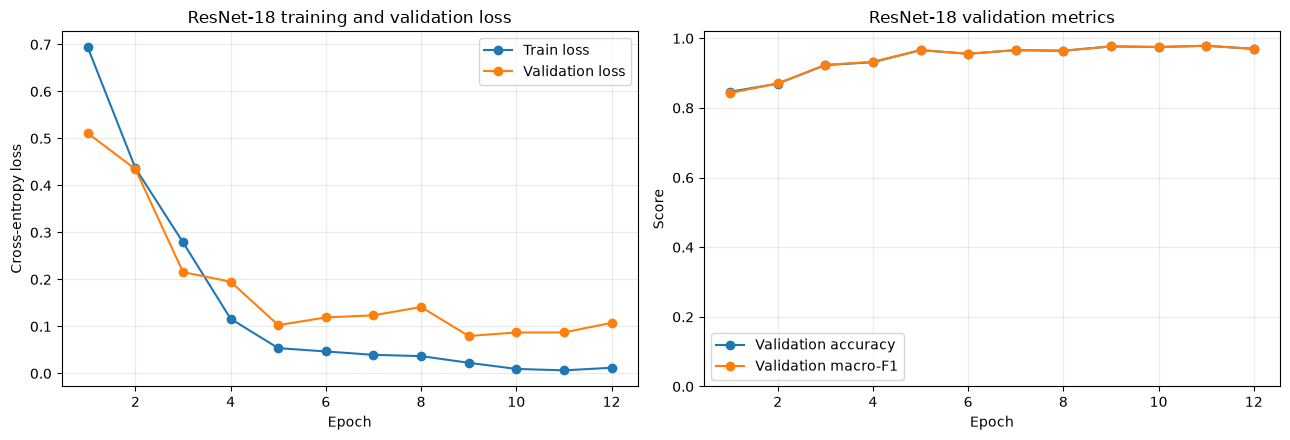

Saved: D:\computer vision\Brain-MRI-Classification\results\visualizations\resnet18_learning_curves.png


In [8]:
history_df = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
axes[0].set_title("ResNet-18 training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation accuracy")
axes[1].plot(history_df["epoch"], history_df["val_f1_macro"], marker="o", label="Validation macro-F1")
axes[1].set_title("ResNet-18 validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
curve_path = VIS_DIR / "resnet18_learning_curves.png"
plt.savefig(curve_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)

## 9. Restore the selected checkpoint and evaluate the official test set

Test results are calculated only after the checkpoint has been selected using validation macro-F1.

In [9]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError("Checkpoint class mapping does not match the current manifest. Retrain or restore matching data.")
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()
print("Loaded checkpoint from epoch:", checkpoint["best_epoch"])
print("Checkpoint validation macro-F1:", f"{checkpoint['best_validation_macro_f1']:.4f}")

# Official test evaluation.
official_metrics, y_test, pred_test, prob_test, test_paths = evaluate_model(
    model, test_loader, criterion, DEVICE, CLASS_NAMES
)
official_predictions = build_prediction_frame(
    test_df, y_test, pred_test, prob_test, CLASS_NAMES, "official_test"
)
print("Official test metrics:")
display(pd.DataFrame([official_metrics]).T.rename(columns={0: "value"}))

# Secondary sensitivity analysis with exact overlaps against train + validation removed.
if len(test_exact_filtered_dataset) > 0:
    filtered_metrics, y_filtered, pred_filtered, prob_filtered, filtered_paths = evaluate_model(
        model, test_exact_filtered_loader, criterion, DEVICE, CLASS_NAMES
    )
    filtered_predictions = build_prediction_frame(
        test_exact_filtered_df, y_filtered, pred_filtered, prob_filtered,
        CLASS_NAMES, "test_exact_duplicate_filtered"
    )
    print("Exact-duplicate-filtered test metrics:")
    display(pd.DataFrame([filtered_metrics]).T.rename(columns={0: "value"}))
else:
    filtered_metrics = None
    y_filtered = pred_filtered = prob_filtered = filtered_paths = None
    filtered_predictions = pd.DataFrame()
    print("No images remain after exact-duplicate filtering; secondary test metrics are unavailable.")

Loaded checkpoint from epoch: 11
Checkpoint validation macro-F1: 0.9786


Official test metrics:


,value
loss,0.503122
accuracy,0.941250
balanced_accuracy,0.941250
precision_macro,0.946359
recall_macro,0.941250
f1_macro,0.940062
num_images,1600.000000
forward_latency_ms_per_image,2.596685
roc_auc_ovr_macro,0.988208


Exact-duplicate-filtered test metrics:


,value
loss,0.503122
accuracy,0.941250
balanced_accuracy,0.941250
precision_macro,0.946359
recall_macro,0.941250
f1_macro,0.940062
num_images,1600.000000
forward_latency_ms_per_image,2.401989
roc_auc_ovr_macro,0.988208


## 10. Class-wise report, confusion matrices and prediction export

The class-wise report and confusion matrix help identify which classes are most frequently confused. The exact-duplicate-filtered evaluation should be interpreted as a sensitivity analysis only.

,precision,recall,f1-score,support
glioma,0.9969,0.8025,0.8892,400.0000
meningioma,0.8770,0.9800,0.9256,400.0000
notumor,0.9217,1.0000,0.9592,400.0000
pituitary,0.9899,0.9825,0.9862,400.0000
accuracy,0.9412,0.9412,0.9412,0.9412
macro avg,0.9464,0.9412,0.9401,1600.0000
weighted avg,0.9464,0.9412,0.9401,1600.0000


Saved class-wise report: D:\computer vision\Brain-MRI-Classification\results\resnet18_classification_report.csv


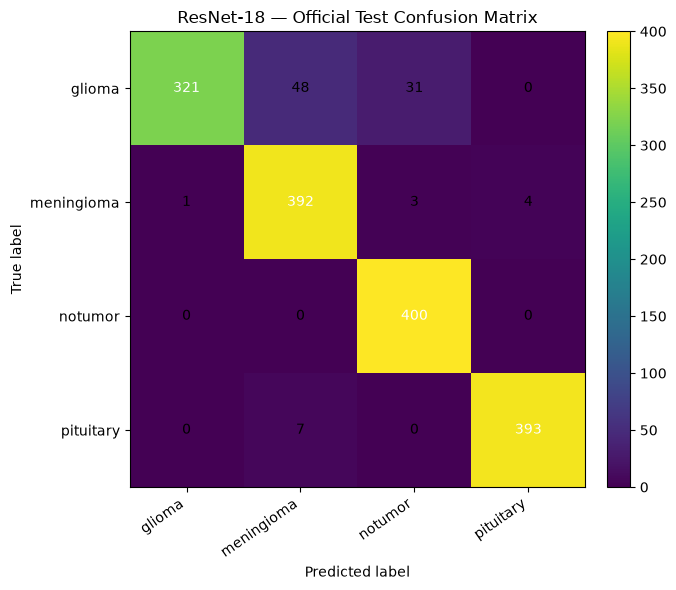

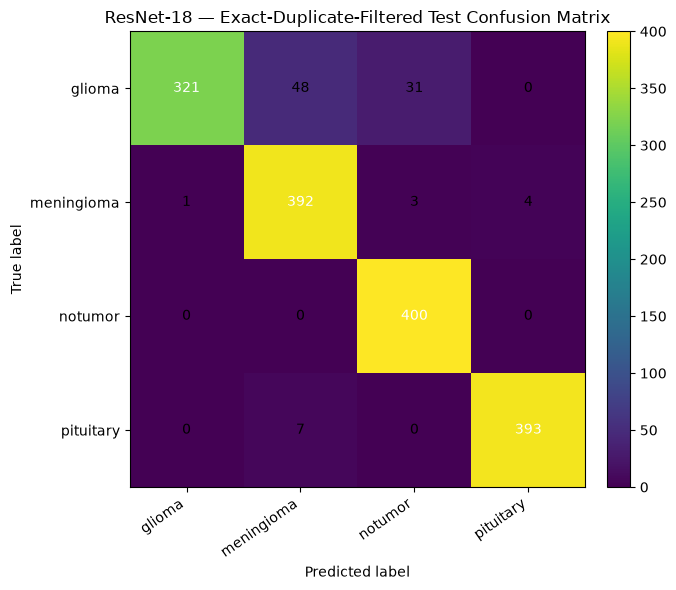

Saved predictions: D:\computer vision\Brain-MRI-Classification\results\resnet18_predictions.csv


,evaluation,relative_path,true_class,predicted_class,correct,probability_glioma,probability_meningioma,probability_notumor,probability_pituitary
0,official_test,Testing/glioma/Te-gl_1.jpg,glioma,notumor,False,0.001645,1.137141e-01,8.585945e-01,2.604606e-02
1,official_test,Testing/glioma/Te-gl_10.jpg,glioma,glioma,True,1.000000,1.539492e-07,6.101858e-08,7.893498e-08
2,official_test,Testing/glioma/Te-gl_100.jpg,glioma,glioma,True,0.999999,7.448722e-08,5.925209e-08,5.122824e-07
3,official_test,Testing/glioma/Te-gl_101.jpg,glioma,glioma,True,0.968241,3.131234e-02,2.985413e-04,1.485070e-04
4,official_test,Testing/glioma/Te-gl_102.jpg,glioma,notumor,False,0.051055,7.102872e-04,9.479360e-01,2.990653e-04
5,official_test,Testing/glioma/Te-gl_103.jpg,glioma,notumor,False,0.008150,1.995963e-01,7.922521e-01,1.533763e-06
6,official_test,Testing/glioma/Te-gl_104.jpg,glioma,glioma,True,0.999859,1.408659e-04,1.782173e-07,9.042685e-11
7,official_test,Testing/glioma/Te-gl_105.jpg,glioma,glioma,True,0.999999,6.330797e-07,1.192561e-08,5.090115e-10
8,official_test,Testing/glioma/Te-gl_106.jpg,glioma,meningioma,False,0.000013,9.615653e-01,3.842204e-02,4.153133e-09
9,official_test,Testing/glioma/Te-gl_107.jpg,glioma,glioma,True,0.999967,3.168553e-05,1.326436e-06,2.283328e-10


In [10]:
class_report = classification_report(
    y_test, pred_test,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
class_report_df = pd.DataFrame(class_report).T
class_report_df.to_csv(REPORT_PATH, index=True)
display(class_report_df.round(4))
print("Saved class-wise report:", REPORT_PATH)

save_confusion_matrix(
    y_test, pred_test, CLASS_NAMES,
    "ResNet-18 — Official Test Confusion Matrix",
    VIS_DIR / "resnet18_confusion_matrix_official_test.png",
)
if filtered_metrics is not None:
    save_confusion_matrix(
        y_filtered, pred_filtered, CLASS_NAMES,
        "ResNet-18 — Exact-Duplicate-Filtered Test Confusion Matrix",
        VIS_DIR / "resnet18_confusion_matrix_exact_filtered_test.png",
    )

prediction_parts = [official_predictions]
if not filtered_predictions.empty:
    prediction_parts.append(filtered_predictions)
predictions_df = pd.concat(prediction_parts, ignore_index=True)
predictions_df.to_csv(PREDICTIONS_PATH, index=False)
print("Saved predictions:", PREDICTIONS_PATH)
display(predictions_df.head(10))

## 11. Grad-CAM example for model interpretability

This cell generates a Grad-CAM heatmap from the final ResNet stage (`layer4[-1]`) for one test image. It selects a misclassified example when one exists; otherwise, it uses the first test image. The heatmap illustrates which regions influence this model's score, but **it does not establish clinical correctness or causal reasoning**.

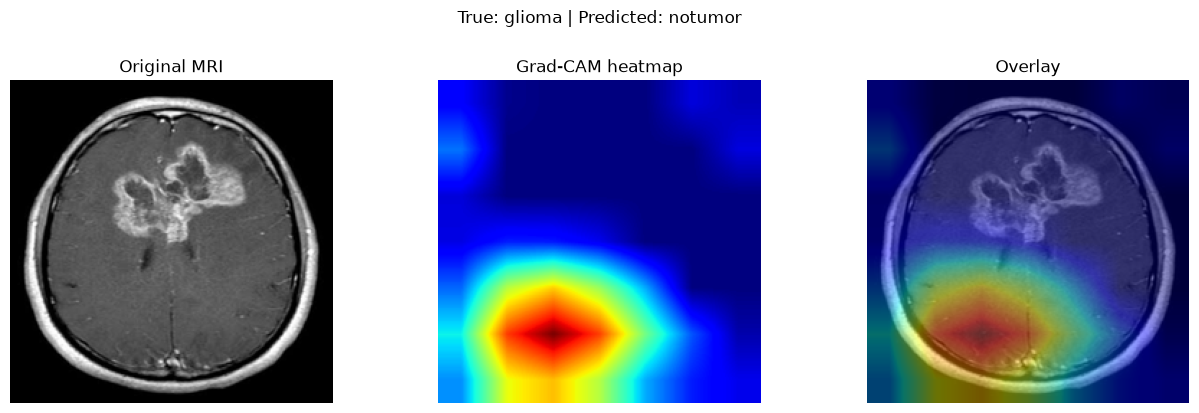

Example image: Testing/glioma/Te-gl_1.jpg
Predicted class probabilities: {'glioma': np.float32(0.0039), 'meningioma': np.float32(0.1275), 'notumor': np.float32(0.8249), 'pituitary': np.float32(0.0437)}
Saved Grad-CAM visualization: D:\computer vision\Brain-MRI-Classification\results\visualizations\resnet18_gradcam_example.png


In [11]:
def compute_gradcam(model, input_tensor, target_layer, target_class=None):
    activations = {}
    gradients = {}

    def forward_hook(_module, _inputs, output):
        activations["value"] = output
        output.register_hook(lambda grad: gradients.__setitem__("value", grad))

    model.eval()
    handle = target_layer.register_forward_hook(forward_hook)
    model.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            logits = model(input_tensor.to(DEVICE))
            predicted_class = int(logits.argmax(dim=1).item())
            class_index = predicted_class if target_class is None else int(target_class)
            logits[0, class_index].backward()

        feature_maps = activations["value"].detach()
        grads = gradients["value"].detach()
        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * feature_maps).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(
            cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
        )[0, 0]
        cam = cam.cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        probabilities = torch.softmax(logits.detach(), dim=1)[0].cpu().numpy()
        return cam, predicted_class, probabilities
    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)


# Prefer a misclassified example to make the error-analysis step useful.
wrong_predictions = predictions_df.loc[
    (predictions_df["evaluation"] == "official_test") & (~predictions_df["correct"])
]
if not wrong_predictions.empty:
    selected_prediction = wrong_predictions.iloc[0]
else:
    selected_prediction = predictions_df.loc[predictions_df["evaluation"] == "official_test"].iloc[0]

selected_path = (DATASET_ROOT / Path(selected_prediction["relative_path"])).resolve()
with Image.open(selected_path) as img:
    original_image = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
input_tensor = EVAL_TRANSFORM(original_image).unsqueeze(0)
cam, gradcam_predicted_idx, gradcam_probabilities = compute_gradcam(
    model, input_tensor, model.layer4[-1]
)

original_array = np.asarray(original_image).astype(np.float32) / 255.0
heatmap_rgb = plt.get_cmap("jet")(cam)[..., :3]
overlay = np.clip(0.55 * original_array + 0.45 * heatmap_rgb, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(original_array)
axes[0].set_title("Original MRI")
axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM heatmap")
axes[2].imshow(overlay)
axes[2].set_title("Overlay")
for ax in axes:
    ax.axis("off")
true_class = selected_prediction["true_class"]
predicted_class = CLASS_NAMES[gradcam_predicted_idx]
fig.suptitle(f"True: {true_class} | Predicted: {predicted_class}", y=1.02)
plt.tight_layout()
gradcam_path = VIS_DIR / "resnet18_gradcam_example.png"
plt.savefig(gradcam_path, dpi=160, bbox_inches="tight")
plt.show()
print("Example image:", selected_prediction["relative_path"])
print("Predicted class probabilities:", dict(zip(CLASS_NAMES, np.round(gradcam_probabilities, 4))))
print("Saved Grad-CAM visualization:", gradcam_path)

## 12. Compare ResNet-18 with the custom CNN baseline

If notebook 02 has produced `custom_cnn_metrics.json`, this cell combines its test metrics with the current ResNet-18 metrics. Both models should use the same manifest partitions; their input normalization and architectures differ appropriately. Compare both official and exact-duplicate-filtered test results, and do not select a model based on test scores.

In [12]:
comparison_rows = []
metric_keys = [
    "accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro",
    "roc_auc_ovr_macro", "forward_latency_ms_per_image", "num_images",
]

if CNN_METRICS_PATH.exists():
    try:
        with CNN_METRICS_PATH.open("r", encoding="utf-8") as file_obj:
            cnn_summary = json.load(file_obj)
        cnn_official = cnn_summary.get("official_test_metrics")
        if cnn_official:
            comparison_rows.append({
                "model": "Custom CNN",
                "evaluation": "official_test",
                **{key: cnn_official.get(key) for key in metric_keys},
            })
        cnn_filtered = cnn_summary.get("exact_duplicate_filtered_test_metrics")
        if cnn_filtered:
            comparison_rows.append({
                "model": "Custom CNN",
                "evaluation": "test_exact_duplicate_filtered",
                **{key: cnn_filtered.get(key) for key in metric_keys},
            })
    except (OSError, json.JSONDecodeError) as exc:
        warnings.warn(f"Could not load custom CNN summary: {exc}")
else:
    print("Custom CNN summary not found; run notebook 02 to generate a direct comparison.")

comparison_rows.append({
    "model": "ResNet-18",
    "evaluation": "official_test",
    **{key: official_metrics.get(key) for key in metric_keys},
})
if filtered_metrics is not None:
    comparison_rows.append({
        "model": "ResNet-18",
        "evaluation": "test_exact_duplicate_filtered",
        **{key: filtered_metrics.get(key) for key in metric_keys},
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(COMPARISON_PATH, index=False)
display(comparison_df.round(4))
print("Saved model comparison:", COMPARISON_PATH)

,model,evaluation,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,forward_latency_ms_per_image,num_images
0,Custom CNN,official_test,0.8800,0.8800,0.8950,0.8800,0.8798,0.9635,3.0180,1600
1,Custom CNN,test_exact_duplicate_filtered,0.8800,0.8800,0.8950,0.8800,0.8798,0.9635,3.1460,1600
2,ResNet-18,official_test,0.9412,0.9412,0.9464,0.9412,0.9401,0.9882,2.5967,1600
3,ResNet-18,test_exact_duplicate_filtered,0.9412,0.9412,0.9464,0.9412,0.9401,0.9882,2.4020,1600


Saved model comparison: D:\computer vision\Brain-MRI-Classification\results\model_comparison.csv


## 13. Export experiment summary

The JSON summary records model weights, configuration, split sizes, selected epoch, and both test evaluations. Only add interpretations to your README after inspecting the curves, confusion matrices, duplicate audit and misclassified examples.

In [13]:
summary = {
    "model": "torchvision_resnet18",
    "seed": int(SEED),
    "class_names": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "weights": weights_name,
    "dataset_root_relative_to_project": (
        str(DATASET_ROOT.relative_to(PROJECT_ROOT))
        if DATASET_ROOT.is_relative_to(PROJECT_ROOT) else str(DATASET_ROOT)
    ),
    "split_manifest": str(SPLIT_PATH.relative_to(PROJECT_ROOT)),
    "split_sizes": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "official_test": int(len(test_df)),
        "test_exact_duplicate_filtered": int(len(test_exact_filtered_df)),
    },
    "validation_selection": {
        "checkpoint_metric": "validation macro-F1",
        "best_epoch": int(checkpoint["best_epoch"]),
        "best_validation_macro_f1": float(checkpoint["best_validation_macro_f1"]),
        "head_only_epochs": int(HEAD_ONLY_EPOCHS),
        "fine_tuned_layers": ["layer4", "fc"],
    },
    "training_config": {
        "img_size": int(IMG_SIZE),
        "batch_size": int(BATCH_SIZE),
        "epochs_requested": int(EPOCHS),
        "epochs_completed": int(len(history_df)),
        "head_learning_rate": float(HEAD_LEARNING_RATE),
        "layer4_learning_rate": float(LAYER4_LEARNING_RATE),
        "weight_decay": float(WEIGHT_DECAY),
        "early_stopping_patience": int(EARLY_STOPPING_PATIENCE),
        "device": str(DEVICE),
        "num_parameters": int(num_parameters),
        "trainable_parameters_after_unfreeze": int(trainable_parameters_after_unfreeze),
        "imagenet_mean": list(IMAGENET_MEAN),
        "imagenet_std": list(IMAGENET_STD),
    },
    "best_checkpoint_path": str(CHECKPOINT_PATH.relative_to(PROJECT_ROOT)),
    "official_test_metrics": official_metrics,
    "exact_duplicate_filtered_test_metrics": filtered_metrics,
    "data_quality_notes": [
        "Reused the train/validation/test manifest from notebook 02.",
        "The exact-duplicate-filtered test set excludes test hashes found in the original training data, represented by train + validation rows.",
        "Exact-hash filtering does not remove all near-duplicates or establish patient-level independence.",
        "This is an educational experiment, not a clinically validated diagnostic model.",
    ],
}
METRICS_PATH.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
print("Saved experiment summary:", METRICS_PATH)

Saved experiment summary: D:\computer vision\Brain-MRI-Classification\results\resnet18_metrics.json


## 14. Completion checklist

- [ ] Reused `results/model_data_split.csv` from notebook 02 without creating a new split.
- [ ] Confirmed no exact SHA-256 group crosses train/validation.
- [ ] Recorded whether ImageNet pretrained weights were used.
- [ ] Selected the checkpoint using validation macro-F1.
- [ ] Reviewed learning curves, class-wise metrics, both confusion matrices and Grad-CAM output.
- [ ] Saved metrics, predictions and `model_comparison.csv`.
- [ ] Added only measured results to the README/resume and preserved the data-quality caveats.

### Next notebook

Proceed to `04_vit_finetuning.ipynb`. Reuse the same manifest. Use the preprocessing expected by the selected ViT weights and compare results with notebook 02/03 without tuning on the test set.